##### Importing the necessary libraries for analysis and visualization

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

###### Loading and viewing the first five rows of the dataset

In [2]:
df = pd.read_csv('house_prices_synthetic.csv')
df.head()

,Bedrooms,Bathrooms,SquareFootage,LotSize,MedianIncome,PropertyTaxRate,ProximityCityCenter,YearBuilt,LastRenovationYear,InterestRate,DemandIndex,Price
0,4,1.6,799,0.62,56347,1.93,18,1980,1980,3.25,1.25,254036.40
1,5,1.9,638,0.67,128725,0.89,18,1959,1972,3.85,1.44,290828.33
2,3,3.6,858,0.89,133844,1.44,21,2005,2017,3.56,0.55,307291.91
3,5,2.0,2022,0.60,121321,1.45,26,2019,2040,5.45,0.51,450113.10
4,5,1.9,3956,0.65,79056,1.26,16,1969,1969,5.72,1.16,780451.24


##### Understanding the dataset

In [3]:
df.shape
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Bedrooms             1000 non-null   int64  
 1   Bathrooms            1000 non-null   float64
 2   SquareFootage        1000 non-null   int64  
 3   LotSize              1000 non-null   float64
 4   MedianIncome         1000 non-null   int64  
 5   PropertyTaxRate      1000 non-null   float64
 6   ProximityCityCenter  1000 non-null   int64  
 7   YearBuilt            1000 non-null   int64  
 8   LastRenovationYear   1000 non-null   int64  
 9   InterestRate         1000 non-null   float64
 10  DemandIndex          1000 non-null   float64
 11  Price                1000 non-null   float64
dtypes: float64(6), int64(6)
memory usage: 93.9 KB


Bedrooms               0
Bathrooms              0
SquareFootage          0
LotSize                0
MedianIncome           0
PropertyTaxRate        0
ProximityCityCenter    0
YearBuilt              0
LastRenovationYear     0
InterestRate           0
DemandIndex            0
Price                  0
dtype: int64

##### We have 1000 houses with full details that is no missing values.
##### We have six columns as floats dtype and six columns with integer dtype making a total of 12 columns 

In [4]:
df.describe()

,Bedrooms,Bathrooms,SquareFootage,LotSize,MedianIncome,PropertyTaxRate,ProximityCityCenter,YearBuilt,LastRenovationYear,InterestRate,DemandIndex,Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,3.004000,2.483700,2830.851000,0.518950,90751.969000,1.463680,15.06300,1986.900000,1993.547000,3.988700,1.004010,590375.191200
std,1.433192,0.855053,1280.926931,0.273001,35681.233019,0.574503,8.26979,21.329063,25.217369,1.126332,0.286503,195555.743686
min,1.000000,1.000000,502.000000,0.050000,30060.000000,0.500000,1.00000,1950.000000,1950.000000,2.000000,0.500000,156857.700000
25%,2.000000,1.700000,1751.500000,0.280000,59220.250000,0.970000,8.00000,1968.750000,1973.000000,3.060000,0.750000,430021.652500
50%,3.000000,2.500000,2950.500000,0.510000,91659.500000,1.450000,15.00000,1986.000000,1993.000000,3.985000,1.000000,600934.570000
75%,4.000000,3.200000,3971.750000,0.750000,122961.750000,1.950000,22.00000,2006.000000,2013.000000,4.940000,1.260000,755478.127500
max,5.000000,4.000000,4998.000000,1.000000,149875.000000,2.500000,29.00000,2022.000000,2071.000000,6.000000,1.500000,962130.020000


In [5]:
df["age"] = 2026 - df["YearBuilt"]
df.head()

,Bedrooms,Bathrooms,SquareFootage,LotSize,MedianIncome,PropertyTaxRate,ProximityCityCenter,YearBuilt,LastRenovationYear,InterestRate,DemandIndex,Price,age
0,4,1.6,799,0.62,56347,1.93,18,1980,1980,3.25,1.25,254036.40,46
1,5,1.9,638,0.67,128725,0.89,18,1959,1972,3.85,1.44,290828.33,67
2,3,3.6,858,0.89,133844,1.44,21,2005,2017,3.56,0.55,307291.91,21
3,5,2.0,2022,0.60,121321,1.45,26,2019,2040,5.45,0.51,450113.10,7
4,5,1.9,3956,0.65,79056,1.26,16,1969,1969,5.72,1.16,780451.24,57


In [6]:
df["age_from_renovation"] = 2026 - df["LastRenovationYear"]
df.head(10)

,Bedrooms,Bathrooms,SquareFootage,LotSize,MedianIncome,PropertyTaxRate,ProximityCityCenter,YearBuilt,LastRenovationYear,InterestRate,DemandIndex,Price,age,age_from_renovation
0,4,1.6,799,0.62,56347,1.93,18,1980,1980,3.25,1.25,254036.40,46,46
1,5,1.9,638,0.67,128725,0.89,18,1959,1972,3.85,1.44,290828.33,67,54
2,3,3.6,858,0.89,133844,1.44,21,2005,2017,3.56,0.55,307291.91,21,9
3,5,2.0,2022,0.60,121321,1.45,26,2019,2040,5.45,0.51,450113.10,7,-14
4,5,1.9,3956,0.65,79056,1.26,16,1969,1969,5.72,1.16,780451.24,57,57
5,2,3.7,2127,0.20,93851,1.53,13,1954,1954,3.21,0.79,497595.54,72,72
6,3,2.7,1803,0.50,128234,1.33,7,1972,1972,5.46,0.75,479903.75,54,54
7,3,1.2,1634,0.73,111502,0.90,1,1958,1958,5.13,0.83,455500.07,68,68
8,3,2.7,2686,0.31,126633,1.32,26,2007,2031,5.72,0.77,531498.35,19,-5
9,5,3.4,3670,0.24,111418,0.64,16,2008,2008,2.98,1.01,731001.87,18,18


In [7]:
df.drop(columns=["LastRenovationYear"], inplace=True)
df.head(10)

/tmp/ipykernel_120980/1834444982.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["LastRenovationYear"], inplace=True)


,Bedrooms,Bathrooms,SquareFootage,LotSize,MedianIncome,PropertyTaxRate,ProximityCityCenter,YearBuilt,InterestRate,DemandIndex,Price,age,age_from_renovation
0,4,1.6,799,0.62,56347,1.93,18,1980,3.25,1.25,254036.40,46,46
1,5,1.9,638,0.67,128725,0.89,18,1959,3.85,1.44,290828.33,67,54
2,3,3.6,858,0.89,133844,1.44,21,2005,3.56,0.55,307291.91,21,9
3,5,2.0,2022,0.60,121321,1.45,26,2019,5.45,0.51,450113.10,7,-14
4,5,1.9,3956,0.65,79056,1.26,16,1969,5.72,1.16,780451.24,57,57
5,2,3.7,2127,0.20,93851,1.53,13,1954,3.21,0.79,497595.54,72,72
6,3,2.7,1803,0.50,128234,1.33,7,1972,5.46,0.75,479903.75,54,54
7,3,1.2,1634,0.73,111502,0.90,1,1958,5.13,0.83,455500.07,68,68
8,3,2.7,2686,0.31,126633,1.32,26,2007,5.72,0.77,531498.35,19,-5
9,5,3.4,3670,0.24,111418,0.64,16,2008,2.98,1.01,731001.87,18,18


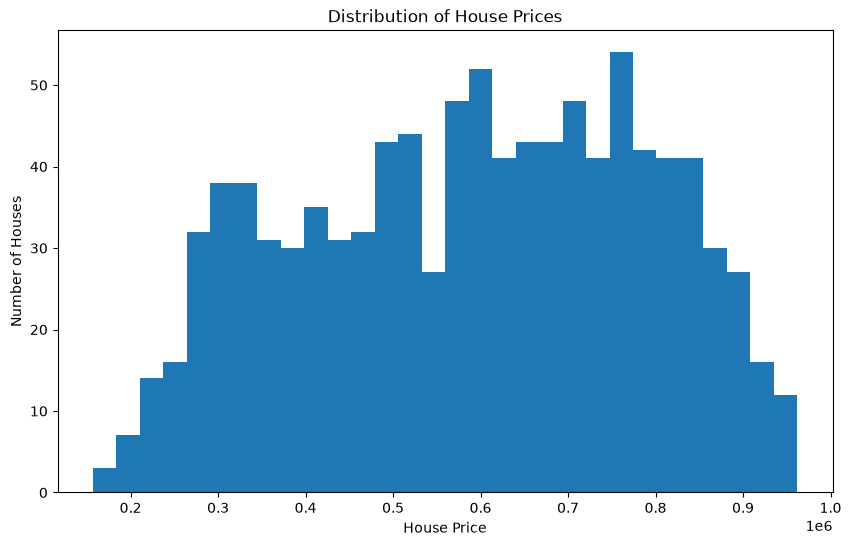

In [8]:
plt.figure(figsize=(10, 6))
plt.hist(df['Price'], bins=30)
plt.title('Distribution of House Prices')
plt.xlabel('House Price')
plt.ylabel('Number of Houses')
plt.show()

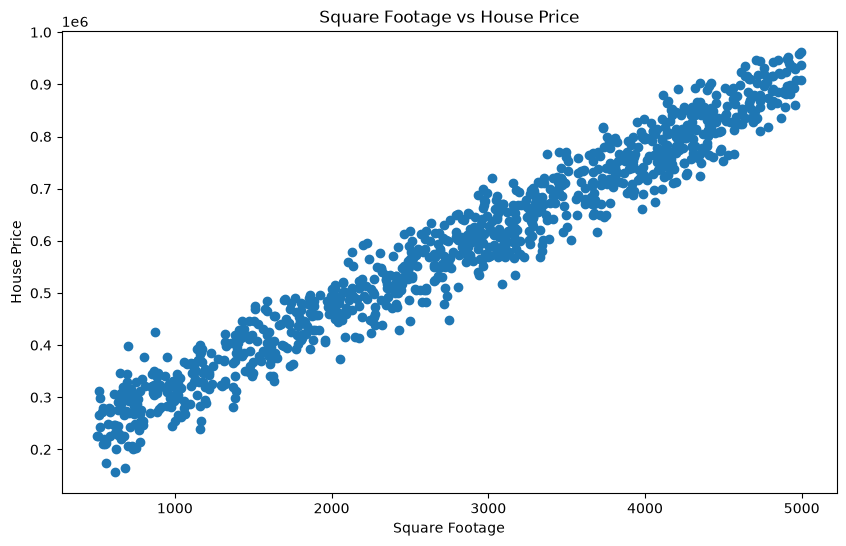

In [9]:
plt.figure(figsize=(10, 6))
plt.scatter(df['SquareFootage'], df['Price'])
plt.title('Square Footage vs House Price')
plt.xlabel('Square Footage')
plt.ylabel('House Price')
plt.show()

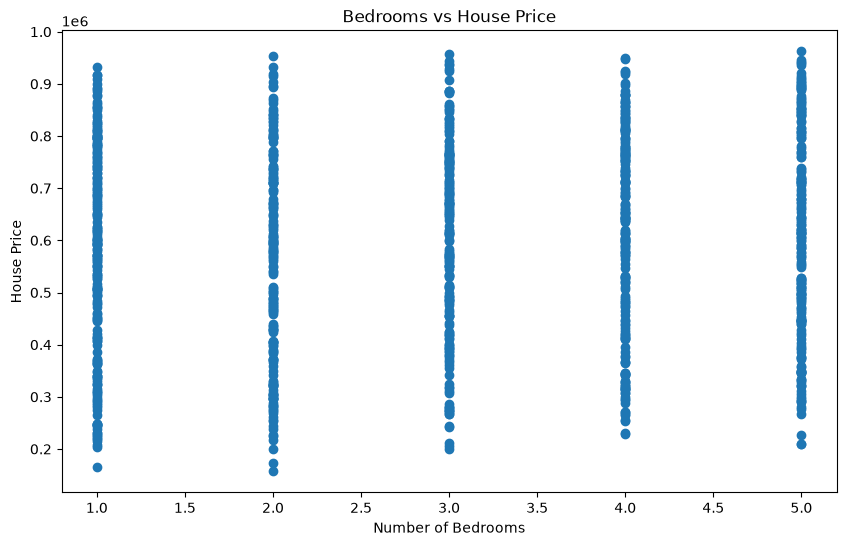

In [10]:
plt.figure(figsize=(10, 6))
plt.scatter(df['Bedrooms'], df['Price'])
plt.title('Bedrooms vs House Price')
plt.xlabel('Number of Bedrooms')
plt.ylabel('House Price')
plt.show()


In [11]:
df['Bedrooms'].corr(df['Price'])

np.float64(0.09122388180086084)

In [12]:
df['SquareFootage'].corr(df['Price'])

np.float64(0.9774765161157263)

In [13]:
df.groupby('Bedrooms')['Price'].agg(['mean', 'median', 'count', 'min', 'max'])

,mean,median,count,min,max
Bedrooms,,,,,
1,573745.138810,591534.585,210,164916.72,932524.13
2,554506.807053,571635.835,190,156857.70,953223.76
3,600295.531842,615921.510,190,200237.27,957332.15
4,615146.303544,642483.290,206,228625.63,949179.00
5,606647.691814,606705.305,204,209525.72,962130.02


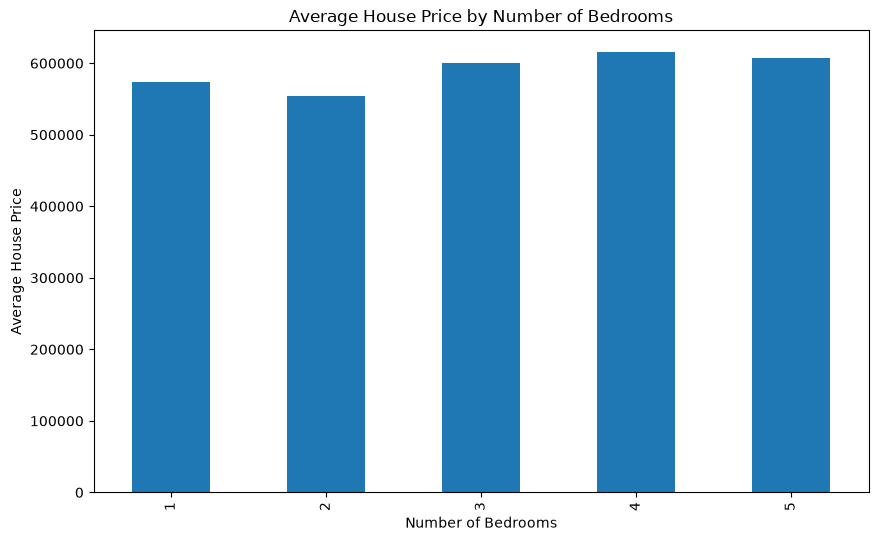

In [14]:
df.groupby('Bedrooms')['Price'].mean().plot(kind='bar', figsize=(10, 6))
plt.title('Average House Price by Number of Bedrooms')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Average House Price')
plt.show()

In [15]:
df.groupby('Bathrooms')['Price'].mean()

Bathrooms
1.0    646807.848750
1.1    631893.684615
1.2    541577.762083
1.3    618241.393784
1.4    562405.783600
1.5    624858.238889
1.6    534833.529667
1.7    519451.602973
1.8    589180.706579
1.9    612729.300357
2.0    521533.640968
2.1    611207.680652
2.2    519509.978276
2.3    618767.085625
2.4    543819.264815
2.5    551342.566000
2.6    587808.214872
2.7    563238.085000
2.8    583945.516765
2.9    585978.725357
3.0    650433.375676
3.1    603518.223500
3.2    538644.855000
3.3    661085.416774
3.4    527536.374400
3.5    673904.233333
3.6    588713.877941
3.7    561767.086207
3.8    633571.985000
3.9    652563.991333
4.0    651375.508000
Name: Price, dtype: float64

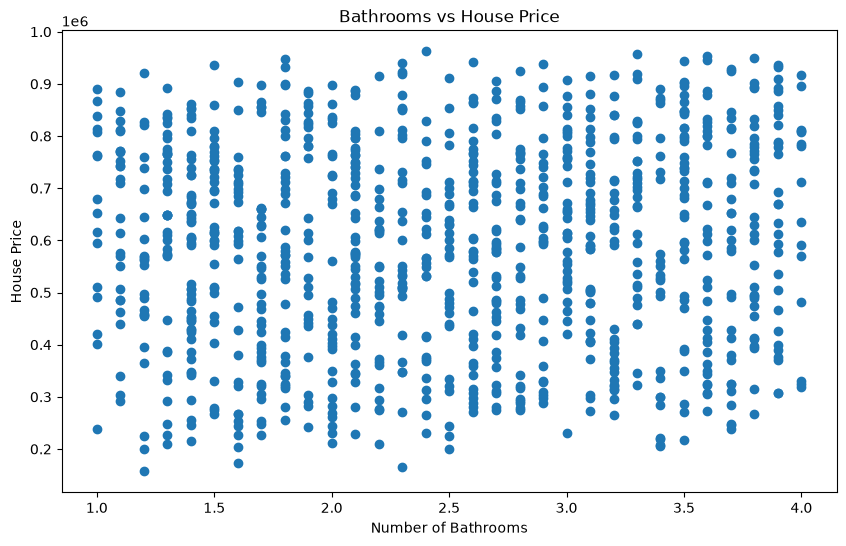

In [16]:
plt.figure(figsize=(10, 6))
plt.scatter(df['Bathrooms'], df['Price'])
plt.title('Bathrooms vs House Price')
plt.xlabel('Number of Bathrooms')
plt.ylabel('House Price')
plt.show()

In [17]:
df["Bathrooms"].corr(df["Price"])

np.float64(0.06270050870214282)

In [18]:
correlation = df.corr(numeric_only=True)
print(correlation["Price"].sort_values(ascending=False))

Price                  1.000000
SquareFootage          0.977477
Bedrooms               0.091224
LotSize                0.085185
MedianIncome           0.064803
Bathrooms              0.062701
DemandIndex            0.029543
InterestRate           0.013121
YearBuilt              0.005772
age_from_renovation   -0.002031
age                   -0.005772
PropertyTaxRate       -0.049079
ProximityCityCenter   -0.107430
Name: Price, dtype: float64


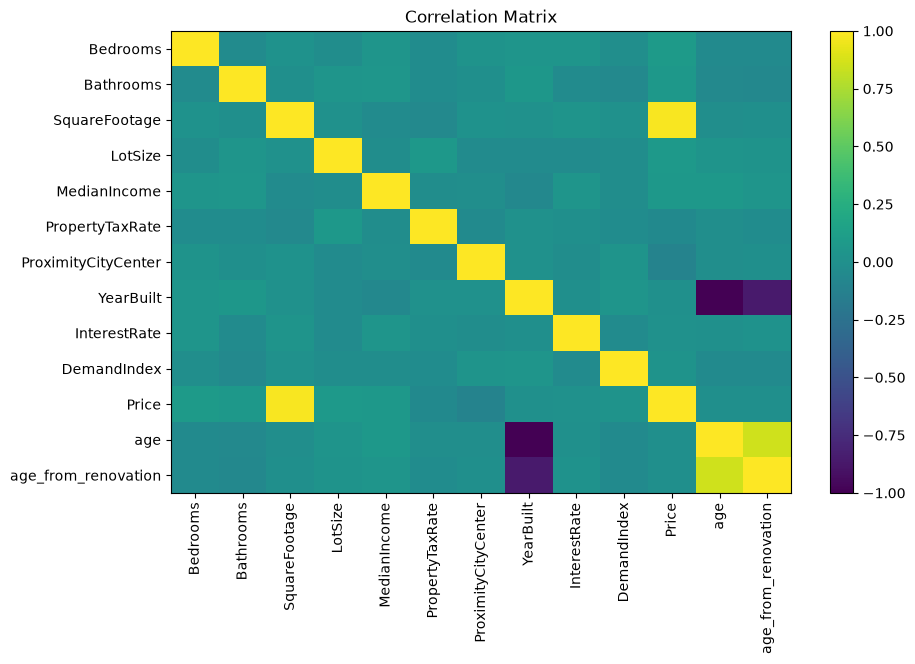

In [19]:
plt.figure(figsize=(10, 6))
plt.imshow(correlation, aspect='auto')
plt.colorbar()
plt.title('Correlation Matrix')
plt.xticks(range(len(correlation)), correlation.columns, rotation=90)
plt.yticks(range(len(correlation)), correlation.columns)
plt.show()

In [20]:
sns.set_theme(style="whitegrid")

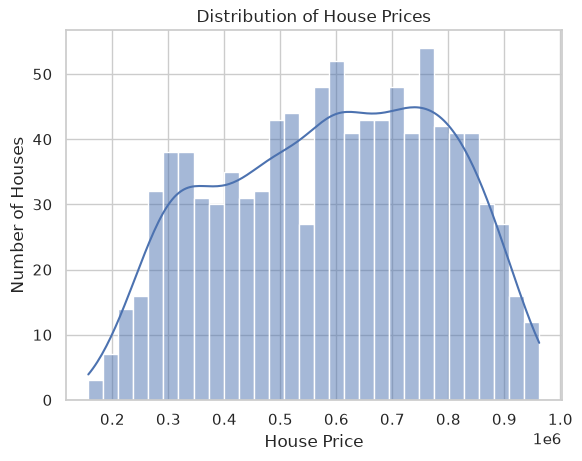

In [21]:
sns.histplot(data=df, x="Price", bins=30, kde=True)
plt.title('Distribution of House Prices')
plt.xlabel('House Price')
plt.ylabel('Number of Houses')
plt.show()

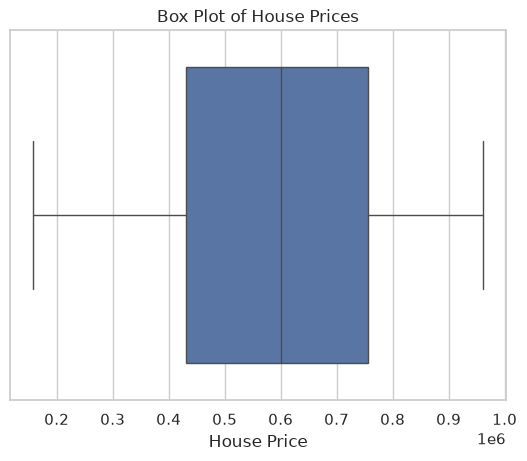

In [22]:
sns.boxplot(data=df, x="Price")
plt.title('Box Plot of House Prices')
plt.xlabel('House Price')
plt.show()

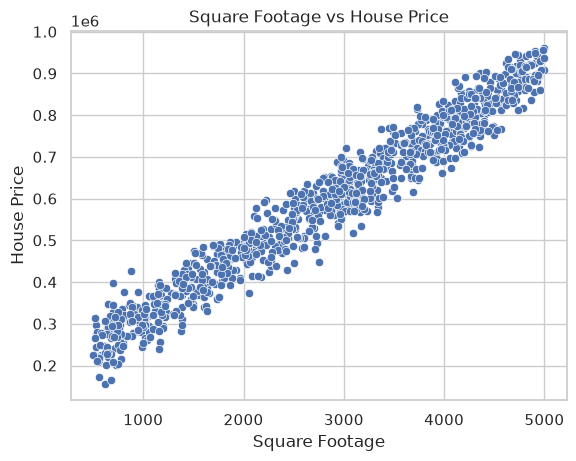

In [23]:
sns.scatterplot(data=df, x="SquareFootage", y="Price")
plt.title('Square Footage vs House Price')
plt.xlabel('Square Footage')
plt.ylabel('House Price')
plt.show()

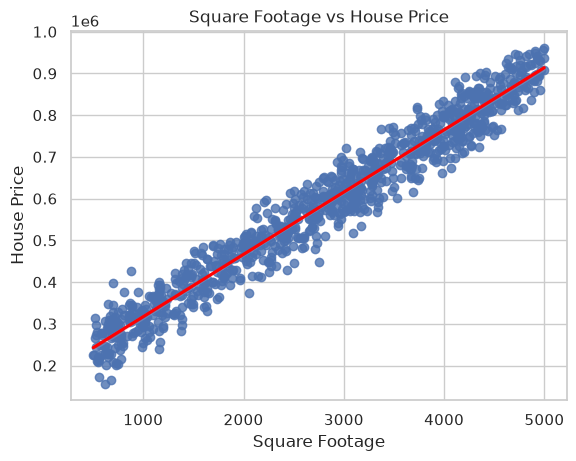

In [26]:
sns.regplot(data=df, x="SquareFootage", y="Price", line_kws={"color": "red"})
plt.title('Square Footage vs House Price')
plt.xlabel('Square Footage')
plt.ylabel('House Price')
plt.show()

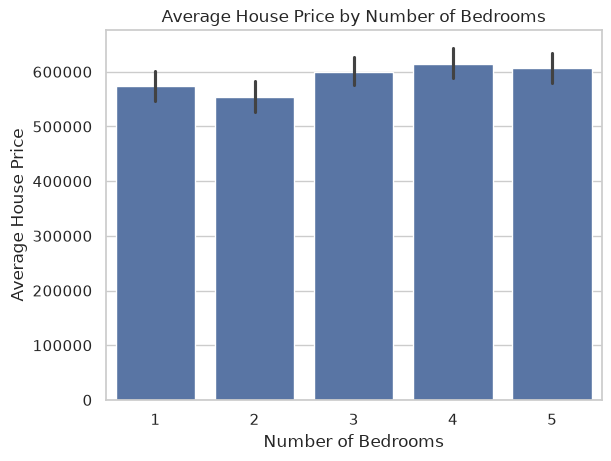

In [28]:
sns.barplot(data=df, x="Bedrooms", y="Price")
plt.title('Average House Price by Number of Bedrooms')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Average House Price')
plt.show()

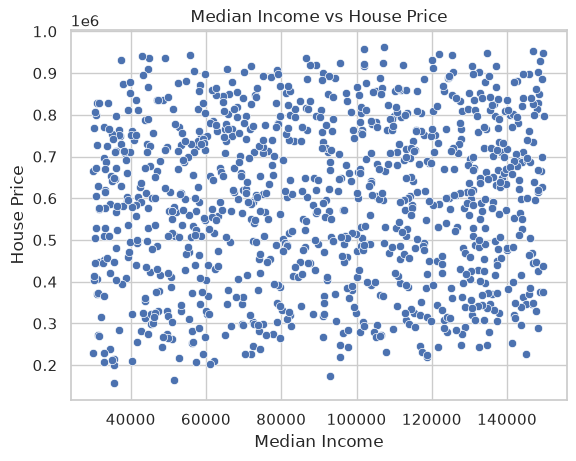

In [29]:
sns.scatterplot(data=df, x="MedianIncome", y="Price")
plt.title('Median Income vs House Price')
plt.xlabel('Median Income')
plt.ylabel('House Price')
plt.show()

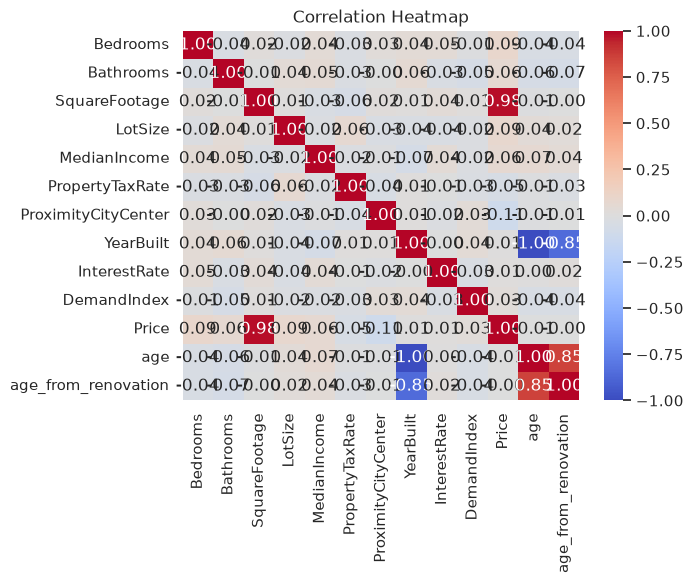

In [33]:
sns.heatmap(data=correlation, annot=True, fmt=".2f", cmap="coolwarm")
plt.title('Correlation Heatmap')
plt.show()